PRODUCT RETURN ANALYSIS
-----------------------
Total Orders: 30
Returned Orders: 14
Overall Return Rate: 46.67%

Category-wise Analysis:
                  Total_Orders  Returned_Orders  Return_Rate
Product_Category                                            
Electronics                  9                6    66.666667
Clothing                     8                4    50.000000
Furniture                    6                2    33.333333
Grocery                      7                2    28.571429

Return Reasons:
Return_Reason
Damaged             4
Wrong Product       2
Size Issue          2
Poor Quality        2
Expired Product     2
Not as Described    1
Changed Mind        1
Name: count, dtype: int64


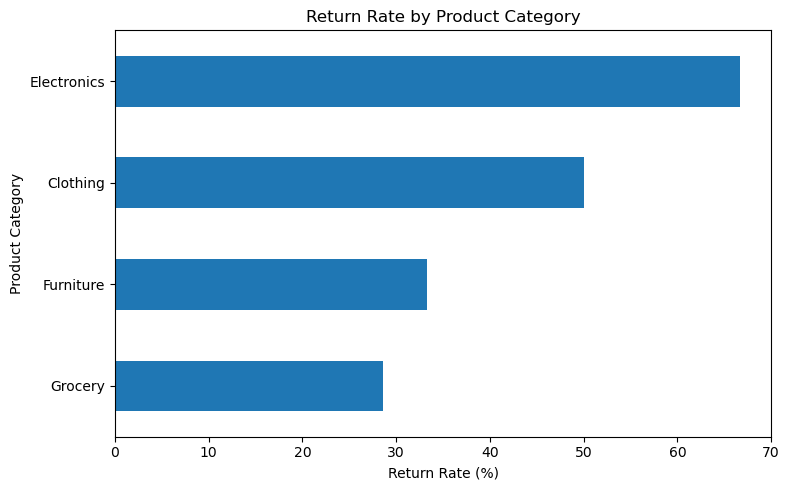

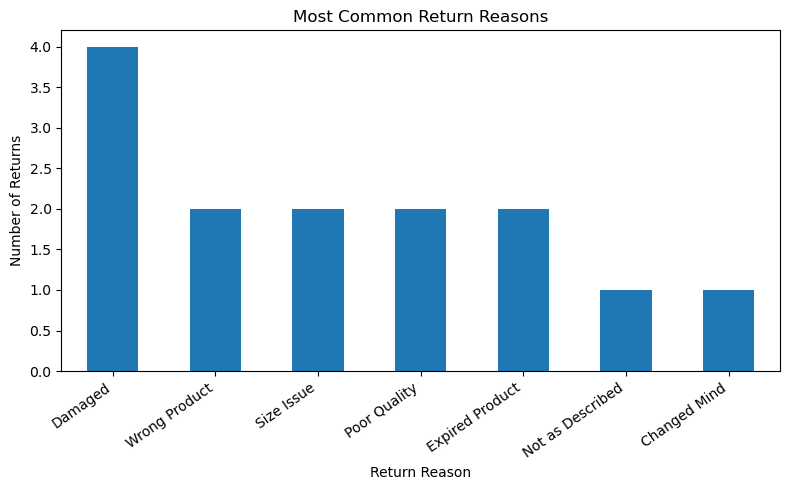


CHI-SQUARE TEST
Chi-square statistic: 2.8316
P-value: 0.4183
Result: Null Hypothesis Rejected. Product Category and Return Status are associated.


In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

# Load dataset

df = pd.read_csv(r"C:\Users\student\Downloads\product_returns.csv")

# Clean column values
df["Product_Category"] = (
    df["Product_Category"].astype(str).str.strip()
)

df["Return_Status"] = (
    df["Return_Status"].astype(str).str.strip().str.title()
)

df["Return_Reason"] = (
    df["Return_Reason"].fillna("Unknown").astype(str).str.strip()
)

# Remove duplicate orders
df = df.drop_duplicates(subset=["Order_ID"])

# Validate return status
df = df[df["Return_Status"].isin(["Yes", "No"])]

# Basic statistics
total_orders = len(df)
returned_orders = (df["Return_Status"] == "Yes").sum()

return_rate = (
    returned_orders / total_orders * 100
    if total_orders > 0 else 0
)

print("PRODUCT RETURN ANALYSIS")
print("-----------------------")
print("Total Orders:", total_orders)
print("Returned Orders:", returned_orders)
print(f"Overall Return Rate: {return_rate:.2f}%")

# Category-wise return analysis
category_summary = df.groupby("Product_Category").agg(
    Total_Orders=("Order_ID", "count"),
    Returned_Orders=(
        "Return_Status",
        lambda x: (x == "Yes").sum()
    )
)

category_summary["Return_Rate"] = (
    category_summary["Returned_Orders"]
    / category_summary["Total_Orders"] * 100
)

print("\nCategory-wise Analysis:")
print(category_summary.sort_values(
    "Return_Rate", ascending=False
))

# Return reasons
returned_df = df[df["Return_Status"] == "Yes"]

reason_counts = returned_df["Return_Reason"].value_counts()

print("\nReturn Reasons:")
print(reason_counts)

# Plot 1: Category-wise return rate
category_summary["Return_Rate"].sort_values().plot(
    kind="barh",
    figsize=(8, 5),
    title="Return Rate by Product Category"
)

plt.xlabel("Return Rate (%)")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

# Plot 2: Return reasons
if not reason_counts.empty:
    reason_counts.plot(
        kind="bar",
        figsize=(8, 5),
        title="Most Common Return Reasons"
    )

    plt.xlabel("Return Reason")
    plt.ylabel("Number of Returns")
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.show()

# Statistical hypothesis testing
contingency_table = pd.crosstab(
    df["Product_Category"],
    df["Return_Status"]
)

if (
    contingency_table.shape[0] >= 2
    and contingency_table.shape[1] == 2
):
    chi2, p_value, dof, expected = chi2_contingency(
        contingency_table
    )

    print("\nCHI-SQUARE TEST")
    print("Chi-square statistic:", round(chi2, 4))
    print("P-value:", round(p_value, 4))

    if p_value < 0.05:
        print(
            "Result: Evidence of an association between "
            "product category and return status."
        )
    else:
        print(
            "Result: Null Hypothesis Rejected. Product Category and Return Status are associated."
        )
else:
    print(
        "Statistical test requires at least two categories "
        "and both returned and non-returned orders."
    )